# PyTorch Workflow Fundamentals

In this module, we're going to cover a standard PyTorch workflow

<!-- ![PyTorch Workflow](../images/01_a_pytorch_workflow.png) -->

```python
TODO

# add table here
```

## Data (Preparing and Loading)

In [ ]:
import torch

weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

# X = torch.arange(start, end, step)

In [ ]:
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = X * weight + bias
X, y

### Spliting data into training and test sets

We've got some data. However, we need to split it up before we build a model. One of the most important steps in a machine learning project is creating a training and test set.



In [ ]:
train_split = int(0.8 * len(X))

X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

In [ ]:
A = list()
for i in range(20):
    A.append(i + 1)

train_split = int(0.8 * len(A))

A_train = A[:train_split]
A_test = A[train_split:]
A_train, A_test

In [ ]:
from matplotlib import pyplot as plt

def plot_predictions(
    train_data: torch.tensor,
    train_labels: torch.tensor,
    test_data: torch.tensor,
    test_labels: torch.tensor,
    predictions=None,
):
    '''
    plots training data, test data and compares predictions
    '''
    plt.figure(figsize=(3,2))

    plt.scatter(train_data, train_labels, c='cyan', s=2, label='Training Data')

    plt.scatter(test_data, test_labels, c='orange', s=2, label='Testing Data')

    if predictions is not None:
        plt.scatter(test_data, predictions, c='r', s=4, label='predictions')

    plt.legend(prop={'size': 14})

### PyTorch model building essentials

PyTorch has four, give or take, essentail modules ywe can use to create almost any kind of neural network we can imagine. They're

| PyTorch module | What does it do? |
|---|---|
| `torch.nn` | Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way). |
| `torch.nn.Parameter` | Stores tensors that can be used with `nn.Module`. If `requires_grad=True` gradients (used for updating model parameters via gradient descent) are calculated automatically, this is often referred to as "autograd". |
| `torch.nn.Module` | The base class for all neural network modules, all the building blocks for neural networks are subclasses. If you're building a neural network in PyTorch, your models should subclass `nn.Module`. Requires a `forward()` method be implemented. |
| `torch.optim` | Contains various optimization algorithms (these tell the model parameters stored in `nn.Parameter` how to best change to improve gradient descent and in turn reduce the loss). |
| `def forward()` | All `nn.Module` subclasses require a `forward()` method, this defines the computation that will take place on the data passed to the particular `nn.Module` (e.g. the linear regression formula above). |

If the above soudns complex, think of liek this, almost everything in PyTorch neural network comes from torch.nn

- `nn.Module` contains the larger building blocks
- `nn.Parameter` contains the smaller parameters like weights and biases
- `forward()` tells the larger blocks how to make calculations on inputs, tensors full of data, within `nn.Module`
- `torch.optim` contains optimization methods on how to improve the parameters within `nn.Parameter` to better represent input data.

In [ ]:
from torch import nn

# creates a linear regression model in PyTorch
class LinearRegressionModel(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.weights = nn.Parameter(
            torch.rand(1, dtype=torch.float32), requires_grad=True
        )  # can we update this value with gradient descent?

        self.bias = nn.Parameter(torch.rand(1, dtype=torch.float32), requires_grad=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.weights + self.bias  # this is linear regression formula

### Checking contents of a PyTorch model

Now we've got these out of the way, let's create a model instance with the class we've made and check its parameters using `.parameters()`

In [ ]:
torch.manual_seed(seed=69)

model_0 = LinearRegressionModel()

list(model_0.parameters())

we can also tget the state (_what the model contains_) of the model using `.state_dict()`.

In [ ]:
model_0.state_dict()

notice how the values for `weights` and `bias` from `model_0.state_dict()` come out as random float tensors?

This is because we initialized them above using torch.randn().

Essentially we want to start from random parameters and get the model to update them towards parameters that fit our data best.

Because our model starts with random values, it will have poor predictive power right now.

### Making predictions using `torch.inference_mode()`

To check this we can pass it the test data X_test to see how closely it predicts y_test. When we pass data to our model, it will go through the model's `forward` method and produce a result using the computation we've defined.

Let's make some predictions

In [ ]:
# Make predictions with model

with torch.inference_mode():
    y_preds = model_0(X_test)

# note: in older PyTorch code you might also see torch.no_grad()
# with torch.no_grad():
#     y_preds = model_0(X_test)

We probably noticed we used `torch.inference_mode()` as a context manager. **_that's what the `with torch.inference_mode():` is_** to make the predictions


As the name suggests, `torch.inference_mode()` is used when using a model for inference _**making predictions**_


`torch.inference_mode()` turns off a bunch of things , **_like gradient tracking, which is necessary for training but not for inference_**m, to make forward-pass,  **_data going through the `forward()` method_**

In [ ]:
# Check the predictions
print(f'number of testing samples: {len(X_test)}')
print(f'number of predictions made: {len(y_preds)}')
print(f'printed values: \n {y_preds}')

In [ ]:
plot_predictions(
    train_data=X_train, 
    train_labels=y_train, 
    test_data=X_test,
    test_labels=y_test, 
    predictions=y_preds
    )

In [ ]:
y_test - y_preds

Woah! Those predictions look pretty bad.

This makes sense though, when you remember our model is just using random parameter values to make predictions.

It hasn't even looked at the blue dots to try to predict the green dots.

Time to change that.

## 3. Train Model

Right now, our model is making predictions using random parameters to make calculations it's basically guessing (randomly). To fix that, we can update its internal parmeters, the `weights` and `bias` values we set randomly using `nn.Parameter()` and `torch.rand()` to be something that better represents data. We could hardcode this but where's the fun in that?

Much of the time we won't know  what the ideal parameters are for a model.

Instead, it's much more fu nto write code to see if the model can try and figure them out itself.


### Creating a loss function and optimizer in PyTorch

For our model to update its parmeters on its own, we'll need to add a few more things to our recipe. That's a loss function a s well as an optimizer. The rools of these are:

- Loss function measures how wrong our model's predictions are compared to the ground truth. PyTorch has plenty of built-in loss functions in `torch.nn`. Mean absoluate error (MAE) for regression and cross entropy for classification.

- Optimizer tells your model how

Let's create a loss function and an optimizer we can use to help improve our model. Depending on what kind of problem we're working on will depend on what loss function and what optimizer we use.

However, there are some common values, that are known to work well such as the stochastic gradient descent or Adam optimizer and mean absolute error loss function for regression problems or binary cross entropy loss function for classification problems.

For our problems, since we're predicting a number, let's use MAE.

In [ ]:
loss_fun = nn.L1Loss() # mae is the same as L1Loss

# create the optimizaer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

### Create an optimization loop in PyTorch

Woohoo! Now we've got a loss function and an optimizer, it's now time to create a training loop (and testing loop)

The training loop involves going through the testing data and eavluating how good the partterns are that the model learned o nthe training data. Each of these is called a loop because we want our model to look at each sample in each dataset.

To create these, we're going to write a Python `for` loop in the theme of the unofficial PyTorch optimization loop song.

Let's sing the PyTorch optimization loop song

> It's train time! \
> do the forward pass \
> calculate the loss, \
> optimizaer zero grad, \
> loss backwards 
>
> Optimizer step step step 
> 
> Let's test now! \
> with torch no grad: \
> do the forward pass, \
> calculate the loss, \
> watch it go down down down!


### PyTorch Training Loop

For the training loop, we'll build the following steps:

| Number | Step name | What does it do? | Code example |
|---|---|---|---|
| 1 | Forward pass | The model goes through all of the training data once, performing its `forward()` function calculations. | `model(x_train)` |
| 2 | Calculate the loss | The model's outputs (predictions) are compared to the ground truth and evaluated to see how wrong they are. | `loss = loss_fn(y_pred, y_train)` |
| 3 | Zero gradients | The optimizers gradients are set to zero (they are accumulated by default) so they can be recalculated for the specific training step. | `optimizer.zero_grad()` |
| 4 | Perform backpropagation on the loss | Computes the gradient of the loss with respect for every model parameter to be updated (each parameter with `requires_grad=True`). This is known as backpropagation, hence "backwards". | `loss.backward()` |
| 5 | Update the optimizer (gradient descent) | Update the parameters with `requires_grad=True` with respect to the loss gradients in order to improve them. | `optimizer.step()` |

- Pass the data through the model for a number of epoches
- pass the data through the model, this will perform the `forward()` method located within the model object.
- Calculate the loss value (how wrong the model's predictions are)
- Zero the optimizer gradients
- Perform backpropagation on the loss function
- Step the optimizer to up[date the model's parameters with respect to the gradients calculated by `loss.backward()`

> - calculate the loss `(loss = ...)` before performing backpropagation on it `(loss.backward())`.
> - zero graduates `(optimizer.zero_grad())` before computing the gradients of the loss with respect to every model parameter `loss.backward())`.
> - step the optimizer `(optimizer.step())` after performing backpropagation on the loss `(loss.backward())`.

For resources to help understand what's happening behind the scenes with backpropagation adn gradient descent, wee the extra-curriculum section.

In [ ]:
torch.manual_seed(69)

epochs = 100

train_loss_values = list()
test_loss_values = list()
epoch_count = list()

for epoch in range(epochs):

    ### training

    # put model in training mode (this is a default state of a model)
    model_0.train()

    # forward pass on training data using the forward() method inside
    y_pred = model_0(X_train)

    # calculate the loss
    loss = loss_fun(y_pred, y_train)

    # zero gradient of the optimizer
    optimizer.zero_grad()

    # loss backwards
    loss.backward()

    # progress the optimizer
    optimizer.step()

    ### testing

    # put the model in evaluation mode
    model_0.eval()

    with torch.inference_mode():
        # forward pass on test_data
        test_pred = model_0(X_test)

        test_loss = loss_fun(test_pred, y_test.type(torch.float32))

        if epoch % 10 == 0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f'epoch: {epoch} | MAE Training Loss: {loss} | MAE Test Loss: {test_loss}')
            


In [ ]:
plt.plot(epoch_count, train_loss_values, label='Train loss')
plt.plot(epoch_count, test_loss_values, label='Test loss')
plt.title('Training and test loss curves')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend()

### Making predicitons with a trained PyTorch model

Once you've trained a model, you'll likely want to make predictions with it. We've already seen a glimpse of this in the training and testing code above, the steps to do it outside ofthe training/testing loop are similar.

There are three things to remember when making predictions with a PyTorch model.

### Making predictions with a trained PyTorch model (inference)

Once we've trained a model, we want to make predictions with it. We've already seen a glipse of this in the training and testing code above, the stpes to do it outside of the training tesing loop are similar. There are three things to remember when making predictions, also called performing inference with a PyTorch model:

- set the model in evaluation mode (model.eval())
- make the predictions using the inference mode context manager
- all predictions should be made with objects on the same device

The first two items make sure all helpful calculations and settings PyTorch uses behind the scenes during training but aren't necessary for inference are turned off. And the third ensures that you won't run into corss-device errors.

In [ ]:
# set the model to evaluation mode
model_0.eval()

# set up inference mode context manager
with torch.inference_mode():

    # make sure the calculations are done with the model and data on the same device in our case, 
    # we haven't setup device-agnostic code yet so our data and model are on the CPU by default.
    # model_0.to(device)
    # X_test = X_test.to(device)
    y_preds = model_0(X_test)

y_preds

tensor([[0.8548],
        [0.8687],
        [0.8826],
        [0.8965],
        [0.9103],
        [0.9242],
        [0.9381],
        [0.9520],
        [0.9659],
        [0.9798]])

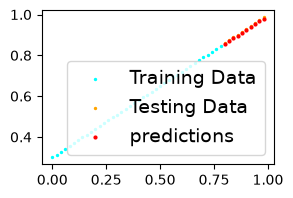

In [22]:
plot_predictions(
    train_data=X_train, 
    train_labels=y_train, 
    test_data=X_test,
    test_labels=y_test, 
    predictions=y_preds
    )

### Saving and Loading a PyTorch model

If we've trained a PyTorch model, chances are that we'll want to save it and export it somewhere

| PyTorch method | What does it do? |
|---|---|
| `torch.save` | Saves a serialized object to disk using Python's `pickle` utility. Models, tensors and various other Python objects like dictionaries can be saved using `torch.save`. |
| `torch.load` | Uses `pickle`'s unpickling features to deserialize and load pickled Python object files (like models, tensors or dictionaries) into memory. You can also set which device to load the object to (CPU, GPU etc). |
| `torch.nn.Module.load_state_dict` | Loads a model's parameter dictionary (`model.state_dict()`) using a saved `state_dict()` object. |

\

> `pickle` module is not secure. That means we should only ever unpickle (load) data we trust. That goes for loading PyTorch models as well. ONly ever use saved PyTorch models from sources we trust.

### Saving a PyTorch model's `state_dict()`

The recommended way for saving and loading a model for inference _(making predictions)_ is by saving and loading a model's `state_dict()`.

Let's see how we can do that in a few steps:


In [ ]:
from pathlib import Path
import os

# MODEL_PATH = Path(os.path.join( Path.home()  'models')


# create models directory


# create model save path


# save the model state dict
print(f'saving model to')